In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import faiss
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
current_path = Path.cwd()
project_root = current_path.parent

processed_data_dir = project_root / "data" / "processed"
metadata_path = processed_data_dir / "selected_product_metadata.csv"
embeddings_path = processed_data_dir / "product_embeddings.npy"

print("Current notebook folder:", current_path)
print("Project root:", project_root)
print("Metadata path:", metadata_path)
print("Embeddings path:", embeddings_path)

Current notebook folder: c:\Users\hunte\VS Code\Visual Product Similarity\notebooks
Project root: c:\Users\hunte\VS Code\Visual Product Similarity
Metadata path: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\selected_product_metadata.csv
Embeddings path: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\product_embeddings.npy


In [3]:
product_metadata = pd.read_csv(metadata_path)

product_embeddings = np.load(embeddings_path)

print("Metadata shape:", product_metadata.shape)
print("Embedding shape:", product_embeddings.shape)
print("Embedding data type:", product_embeddings.dtype)

Metadata shape: (3095, 12)
Embedding shape: (3095, 1280)
Embedding data type: float32


In [4]:
print("Metadata columns:")

for column_name in product_metadata.columns:
    print(column_name)

Metadata columns:
image_id
class_id
super_class_id
path
category_name
full_path
image_exists
width
height
mode
format
is_corrupted


In [ ]:
embedding_norms_before = np.linalg.norm(product_embeddings[:5],axis=1)

print("First 5 embedding lengths before normalisation:")
print(embedding_norms_before)

First 5 embedding lengths before normalisation:
[10.01548  10.01548  10.01548  10.01548  10.202413]


In [6]:
embeddings_copy = product_embeddings.copy()

embedding_norms = np.linalg.norm(
    embeddings_copy,
    axis=1,
    keepdims=True
)

normalised_embeddings = embeddings_copy / embedding_norms

print("Normalised embedding shape:", normalised_embeddings.shape)
print("Normalised data type:", normalised_embeddings.dtype)

Normalised embedding shape: (3095, 1280)
Normalised data type: float32


In [7]:
embedding_norms_after = np.linalg.norm(
    normalised_embeddings[:5],
    axis=1
)

print("First 5 embedding lengths after normalisation:")
print(embedding_norms_after)

First 5 embedding lengths after normalisation:
[1. 1. 1. 1. 1.]


In [8]:
print("FAISS version:", faiss.__version__)

FAISS version: 1.14.3


In [9]:
embedding_dimension = normalised_embeddings.shape[1]

hnsw_m = 32

faiss_index = faiss.IndexHNSWFlat(
    embedding_dimension,
    hnsw_m,
    faiss.METRIC_INNER_PRODUCT
)

faiss_index.hnsw.efConstruction = 80
faiss_index.hnsw.efSearch = 64

print("HNSW ANN index created successfully")
print("Index dimension:", faiss_index.d)
print("Vectors currently inside index:", faiss_index.ntotal)
print("HNSW M:", hnsw_m)
print("efConstruction:", faiss_index.hnsw.efConstruction)
print("efSearch:", faiss_index.hnsw.efSearch)

HNSW ANN index created successfully
Index dimension: 1280
Vectors currently inside index: 0
HNSW M: 32
efConstruction: 80
efSearch: 64


In [10]:
faiss_index.add(
    normalised_embeddings
)

print("Embeddings added successfully")
print("Vectors inside FAISS index:", faiss_index.ntotal)
print("Expected vectors:", len(normalised_embeddings))

Embeddings added successfully
Vectors inside FAISS index: 3095
Expected vectors: 3095


In [11]:
faiss_index_path = (
    processed_data_dir
    / "product_faiss_hnsw_index.index"
)

faiss.write_index(
    faiss_index,
    str(faiss_index_path)
)

print("HNSW ANN index saved successfully")
print("Saved at:", faiss_index_path)
print("File exists:", faiss_index_path.exists())

HNSW ANN index saved successfully
Saved at: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\product_faiss_hnsw_index.index
File exists: True


In [12]:
loaded_faiss_index = faiss.read_index(
    str(faiss_index_path)
)

loaded_faiss_index.hnsw.efSearch = 64

print("HNSW ANN index loaded successfully")
print("Loaded index type:", type(loaded_faiss_index))
print("Vectors inside loaded index:", loaded_faiss_index.ntotal)
print("Index dimension:", loaded_faiss_index.d)
print("efSearch:", loaded_faiss_index.hnsw.efSearch)

HNSW ANN index loaded successfully
Loaded index type: <class 'faiss.swigfaiss.IndexHNSWFlat'>
Vectors inside loaded index: 3095
Index dimension: 1280
efSearch: 64


In [13]:
query_index = 0

query_row = product_metadata.iloc[query_index]

print("Query FAISS position:", query_index)
print("Image ID:", query_row["image_id"])
print("Class ID:", query_row["class_id"])
print("Category:", query_row["category_name"])
print("Relative path:", query_row["path"])
print("Full path:", query_row["full_path"])

Query FAISS position: 0
Image ID: 84
Class ID: 16
Category: bicycle
Relative path: bicycle_final/111645993618_0.JPG
Full path: c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111645993618_0.JPG


In [14]:
query_embedding = normalised_embeddings[
    query_index:query_index + 1
]

print("Query embedding shape:", query_embedding.shape)
print("Query embedding data type:", query_embedding.dtype)

print(
    "Query embedding length:",
    np.linalg.norm(query_embedding)
)

Query embedding shape: (1, 1280)
Query embedding data type: float32
Query embedding length: 0.99999994


In [15]:
top_k = 5

similarity_scores, neighbour_indices = loaded_faiss_index.search(
    query_embedding,
    top_k + 1
)

print("Similarity scores shape:", similarity_scores.shape)
print("Neighbour indices shape:", neighbour_indices.shape)

print("\nSimilarity scores:")
print(similarity_scores)

print("\nNeighbour indices:")
print(neighbour_indices)

Similarity scores shape: (1, 6)
Neighbour indices shape: (1, 6)

Similarity scores:
[[1.0000001  1.0000001  1.0000001  1.0000001  0.7984956  0.79774266]]

Neighbour indices:
[[  3   2   1   0 165 106]]


In [16]:
result_indices = neighbour_indices[0]
result_scores = similarity_scores[0]

filtered_indices = []
filtered_scores = []

for index, score in zip(result_indices, result_scores):
    if index != query_index:
        filtered_indices.append(int(index))
        filtered_scores.append(float(score))

filtered_indices = filtered_indices[:top_k]
filtered_scores = filtered_scores[:top_k]

print("Filtered neighbour indices:", filtered_indices)
print("Filtered similarity scores:", filtered_scores)

Filtered neighbour indices: [3, 2, 1, 165, 106]
Filtered similarity scores: [1.0000001192092896, 1.0000001192092896, 1.0000001192092896, 0.7984955906867981, 0.7977426648139954]


In [17]:
recommended_products = product_metadata.iloc[
    filtered_indices
].copy()

recommended_products["similarity_score"] = filtered_scores

recommended_products[
    [
        "image_id",
        "class_id",
        "category_name",
        "path",
        "similarity_score"
    ]
]

,image_id,class_id,category_name,path,similarity_score
3,87,16,bicycle,bicycle_final/111645993618_3.JPG,1.000000
2,86,16,bicycle,bicycle_final/111645993618_2.JPG,1.000000
1,85,16,bicycle,bicycle_final/111645993618_1.JPG,1.000000
165,2207,320,bicycle,bicycle_final/171780255323_0.JPG,0.798496
106,1629,238,bicycle,bicycle_final/151736367388_0.JPG,0.797743


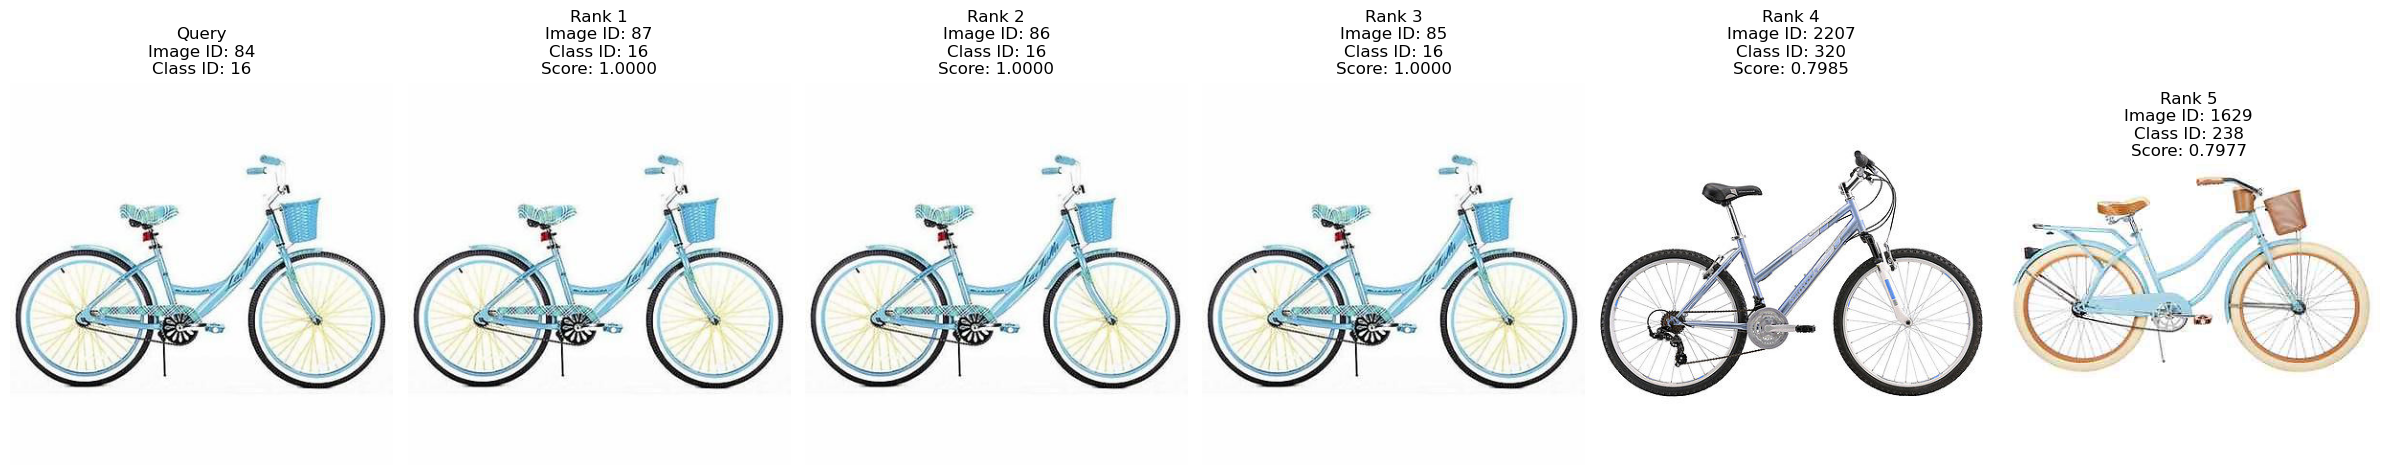

In [ ]:
total_images_to_show = top_k + 1

plt.figure(figsize=(4 * total_images_to_show, 5))

# Display query image
query_image_path = Path(query_row["full_path"])

with Image.open(query_image_path) as query_image:
    plt.subplot(1, total_images_to_show, 1)
    plt.imshow(query_image)
    plt.title(
        f"Query\nImage ID: {query_row['image_id']}\n"
        f"Class ID: {query_row['class_id']}"
    )
    plt.axis("off")

# Display Top-K recommendations
for rank, (neighbour_index, similarity_score) in enumerate(
    zip(filtered_indices, filtered_scores), start=1
):
    recommendation_row = product_metadata.iloc[neighbour_index]
    recommendation_path = Path(recommendation_row["full_path"])

    with Image.open(recommendation_path) as recommendation_image:
        plt.subplot(1, total_images_to_show, rank + 1)
        plt.imshow(recommendation_image)
        plt.title(
            f"Rank {rank}\nImage ID: {recommendation_row['image_id']}\n"
            f"Class ID: {recommendation_row['class_id']}\n"
            f"Score: {similarity_score:.4f}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def retrieve_similar_products(
    query_index,
    faiss_index,
    normalised_embeddings,
    product_metadata,
    top_k=5,
    category_filter=None
):
    query_embedding = normalised_embeddings[query_index:query_index + 1]

    if category_filter is None:
        number_to_search = top_k + 1
    else:
        number_to_search = faiss_index.ntotal

    similarity_scores, neighbour_indices = faiss_index.search(
        query_embedding, number_to_search
    )

    filtered_indices = []
    filtered_scores = []

    for index, score in zip(neighbour_indices[0], similarity_scores[0]):
        index = int(index)
        score = float(score)

        # Remove the exact query image
        if index == query_index:
            continue

        candidate_row = product_metadata.iloc[index]

        # Apply category filter only when one is supplied
        if category_filter is not None and candidate_row["category_name"] != category_filter:
            continue

        filtered_indices.append(index)
        filtered_scores.append(score)

        # Stop after collecting Top-K valid results
        if len(filtered_indices) == top_k:
            break

    results = (
        product_metadata
        .iloc[filtered_indices]
        .copy()
        .reset_index(drop=True)
    )

    results["similarity_score"] = filtered_scores
    results["faiss_index"] = filtered_indices
    results["rank"] = range(1, len(results) + 1)

    return results

In [20]:
query_index = 0

top_results = retrieve_similar_products(
    query_index=query_index,
    faiss_index=loaded_faiss_index,
    normalised_embeddings=normalised_embeddings,
    product_metadata=product_metadata,
    top_k=5
)

top_results[
    [
        "rank",
        "faiss_index",
        "image_id",
        "class_id",
        "category_name",
        "similarity_score"
    ]
]

,rank,faiss_index,image_id,class_id,category_name,similarity_score
0,1,3,87,16,bicycle,1.000000
1,2,2,86,16,bicycle,1.000000
2,3,1,85,16,bicycle,1.000000
3,4,165,2207,320,bicycle,0.798496
4,5,106,1629,238,bicycle,0.797743


In [ ]:
def display_recommendations(
    query_index,
    results,
    product_metadata
):
    query_row = product_metadata.iloc[query_index]
    total_images = len(results) + 1

    plt.figure(figsize=(4 * total_images, 5))

    # Query image
    query_path = Path(query_row["full_path"])

    with Image.open(query_path) as query_image:
        plt.subplot(1, total_images, 1)
        plt.imshow(query_image)
        plt.title(
            f"Query\nImage ID: {query_row['image_id']}\n"
            f"Class ID: {query_row['class_id']}"
        )
        plt.axis("off")

    # Recommended images
    for position, result_row in results.iterrows():
        recommendation_path = Path(result_row["full_path"])

        with Image.open(recommendation_path) as recommendation_image:
            plt.subplot(1, total_images, position + 2)
            plt.imshow(recommendation_image)
            plt.title(
                f"Rank {result_row['rank']}\n"
                f"Image ID: {result_row['image_id']}\n"
                f"Class ID: {result_row['class_id']}\n"
                f"Score: {result_row['similarity_score']:.4f}"
            )
            plt.axis("off")

    plt.tight_layout()
    plt.show()

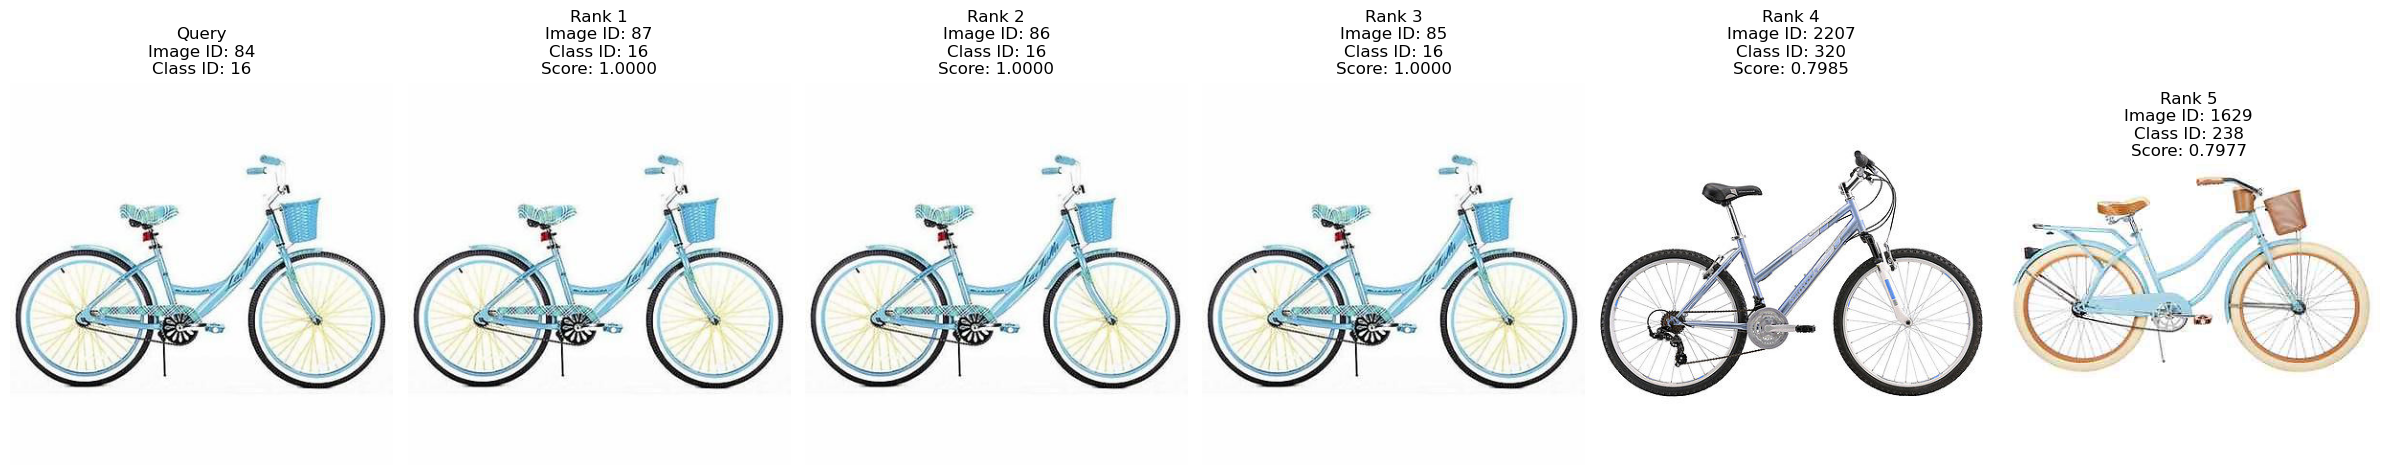

In [28]:
display_recommendations(
    query_index=query_index,
    results=top_results,
    product_metadata=product_metadata
)

In [23]:
results_without_filter = retrieve_similar_products(
    query_index=0,
    faiss_index=loaded_faiss_index,
    normalised_embeddings=normalised_embeddings,
    product_metadata=product_metadata,
    top_k=5
)

results_without_filter[
    [
        "rank",
        "image_id",
        "class_id",
        "category_name",
        "similarity_score"
    ]
]

,rank,image_id,class_id,category_name,similarity_score
0,1,87,16,bicycle,1.000000
1,2,86,16,bicycle,1.000000
2,3,85,16,bicycle,1.000000
3,4,2207,320,bicycle,0.798496
4,5,1629,238,bicycle,0.797743


In [24]:
cabinet_results = retrieve_similar_products(
    query_index=0,
    faiss_index=loaded_faiss_index,
    normalised_embeddings=normalised_embeddings,
    product_metadata=product_metadata,
    top_k=5,
    category_filter="cabinet"
)

cabinet_results[
    [
        "rank",
        "image_id",
        "class_id",
        "category_name",
        "similarity_score"
    ]
]

,rank,image_id,class_id,category_name,similarity_score
0,1,7037,1105,cabinet,0.062873
1,2,6528,1021,cabinet,0.034142
2,3,8152,1274,cabinet,-0.015704
3,4,8719,1364,cabinet,-0.027357


In [25]:
mug_query_index = product_metadata[
    product_metadata["category_name"] == "mug"
].index[0]

print("Mug query index:", mug_query_index)

print(
    product_metadata.iloc[mug_query_index][
        [
            "image_id",
            "class_id",
            "category_name",
            "path"
        ]
    ]
)

Mug query index: 1803
image_id                                35206
class_id                                 6201
category_name                             mug
path             mug_final/111641075307_0.JPG
Name: 1803, dtype: object


In [26]:
mug_results = retrieve_similar_products(
    query_index=mug_query_index,
    faiss_index=loaded_faiss_index,
    normalised_embeddings=normalised_embeddings,
    product_metadata=product_metadata,
    top_k=5
)

mug_results[
    [
        "rank",
        "image_id",
        "class_id",
        "category_name",
        "similarity_score"
    ]
]

,rank,image_id,class_id,category_name,similarity_score
0,1,35209,6201,mug,0.944914
1,2,35207,6201,mug,0.892060
2,3,35208,6201,mug,0.872815
3,4,35210,6201,mug,0.855485
4,5,41201,7384,mug,0.461544


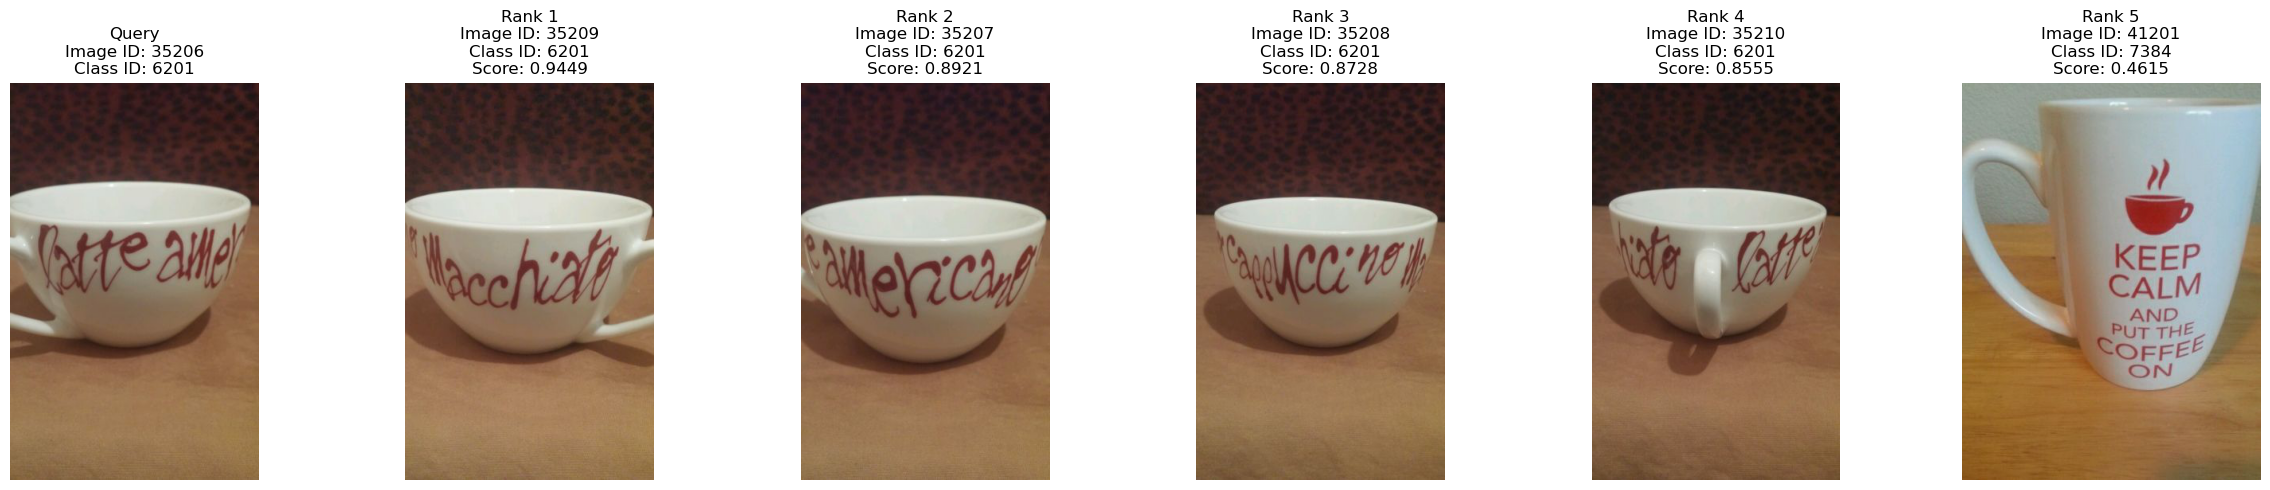

In [27]:
display_recommendations(
    query_index=mug_query_index,
    results=mug_results,
    product_metadata=product_metadata
)